# Classification Track — Telco Customer Churn (Part B + Consolidated Comparison)
**23CSE301 Machine Learning Capstone — Review 2**

**Dataset:** `data/telco_churn.csv` | **Target:** `Churn` (Yes/No) — binary classification.

This notebook continues from Part A (`classification.ipynb`). It covers:
1. Re-creating the **identical** cleaning, feature engineering, stratified 80:20 split and preprocessor used in Part A (`random_state=42`), so every model is compared on the same test set.
2. **Part B algorithms:** Random Forest, AdaBoost, Gradient Boosting, Bagging (Decision Tree base), MLP.
3. The **consolidated 10-algorithm comparison table** (Accuracy, Precision, Recall, F1, ROC-AUC) — deliverable D6 / rubric A2.
4. **5-fold cross-validation** for the two best models, **hyperparameter tuning**, and **final model selection** with justification (rubric A3).

## 0. Imports & Setup

In [6]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Part A models (re-trained here so the consolidated table is produced in one place)
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC

# Part B models
from sklearn.ensemble import (RandomForestClassifier, AdaBoostClassifier,
                              GradientBoostingClassifier, BaggingClassifier)
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, roc_auc_score, RocCurveDisplay,
    classification_report
)

RANDOM_STATE = 42
sns.set_theme(style='whitegrid', palette='colorblind')
plt.rcParams['figure.dpi'] = 100


## 1. Data Loading & Preprocessing (identical to Part A)
Same cleaning, engineered feature (`NumServices`), stratified split and preprocessor as Part A.
Scaler and encoder live inside the `ColumnTransformer`, which sits inside each `Pipeline`, so they are
**fitted on the training set only** (no data leakage), including inside cross-validation folds.

In [7]:
df = pd.read_csv('../data/telco_churn.csv')
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df = df.drop_duplicates().reset_index(drop=True)

# Cleaning: brand-new customers (tenure = 0) have not been billed yet -> TotalCharges = 0
df.loc[(df['tenure'] == 0) & (df['TotalCharges'].isnull()), 'TotalCharges'] = 0
df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].median())
print('Shape:', df.shape, '| Remaining nulls:', df.isnull().sum().sum())

# Engineered feature: NumServices = number of active services/add-ons (same as Part A)
service_cols = ['PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
                'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']
inactive = ['No', 'No internet service', 'No phone service']
df['NumServices'] = df[service_cols].apply(lambda r: sum(v not in inactive for v in r), axis=1)

num_features = ['tenure', 'MonthlyCharges', 'TotalCharges', 'NumServices']
target = 'Churn'
feature_cols = [c for c in df.columns if c not in ['customerID', target]]
cat_features = [c for c in feature_cols if c not in num_features]

X = df[feature_cols]
y = (df[target] == 'Yes').astype(int)   # 1 = churned

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
print('Train:', X_train.shape, ' Test:', X_test.shape)
print('Train churn rate:', round(y_train.mean(), 3), '| Test churn rate:', round(y_test.mean(), 3))

preprocessor = ColumnTransformer(transformers=[
    ('num', StandardScaler(), num_features),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_features),
])

Shape: (7043, 21) | Remaining nulls: 0
Train: (5634, 20)  Test: (1409, 20)
Train churn rate: 0.265 | Test churn rate: 0.265


## 2. Reusable Evaluation Helpers
One function trains a pipeline and returns every mandatory metric, so Part A and Part B are
scored in exactly the same way. Metrics: Accuracy, weighted Precision/Recall/F1, ROC-AUC, confusion matrix.
(For this binary problem ROC-AUC uses the churn-class probability; for multi-class it would be One-vs-Rest.)

In [9]:
def evaluate_model(name, estimator, X_tr, y_tr, X_te, y_te):
    """Fit preprocessing + estimator on train, evaluate on the held-out test set."""
    pipe = Pipeline([('prep', preprocessor), ('model', estimator)])
    pipe.fit(X_tr, y_tr)
    preds = pipe.predict(X_te)
    proba = pipe.predict_proba(X_te)[:, 1]
    row = {
        'Algorithm': name,
        'Accuracy': accuracy_score(y_te, preds),
        'Precision': precision_score(y_te, preds, average='weighted'),
        'Recall': recall_score(y_te, preds, average='weighted'),
        'F1 (weighted)': f1_score(y_te, preds, average='weighted'),
        'ROC-AUC': roc_auc_score(y_te, proba),
    }
    return row, pipe, proba

def style_table(d):
    num = d.select_dtypes('number').columns.drop('Rank', errors='ignore')
    return (d.style.format({c: '{:.4f}' for c in num})
             .background_gradient(subset=['F1 (weighted)', 'ROC-AUC'], cmap='Greens'))

## 3. Part A Models (re-trained for the consolidated table)
Same settings as the Part A notebook, re-fitted here on the identical split so the final table is
self-contained and reproducible.

In [10]:
models_partA = {
    '1. Logistic Regression': LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    '2. K-Nearest Neighbors': KNeighborsClassifier(n_neighbors=11),
    '3. Naive Bayes (Gaussian)': GaussianNB(),
    '4. Decision Tree Classifier': DecisionTreeClassifier(max_depth=6, random_state=RANDOM_STATE),
    '5. Support Vector Machine (SVC)': SVC(C=1.0, kernel='rbf', probability=True, random_state=RANDOM_STATE),
}

results, fitted, probas = [], {}, {}
for name, est in models_partA.items():
    row, pipe, proba = evaluate_model(name, est, X_train, y_train, X_test, y_test)
    results.append(row); fitted[name] = pipe; probas[name] = proba

pd.DataFrame(results)

,Algorithm,Accuracy,Precision,Recall,F1 (weighted),ROC-AUC
0,1. Logistic Regression,0.806246,0.798781,0.806246,0.801064,0.841848
1,2. K-Nearest Neighbors,0.774308,0.772051,0.774308,0.773119,0.811674
2,3. Naive Bayes (Gaussian),0.694819,0.796504,0.694819,0.712652,0.806846
3,4. Decision Tree Classifier,0.792051,0.781271,0.792051,0.783849,0.835000
4,5. Support Vector Machine (SVC),0.791341,0.779302,0.791341,0.781418,0.794026


## 4. Section A1 — Classification Part B (5 Algorithms)

| # | Algorithm | Key idea | Initial settings (tuned later in Section 8) |
|---|---|---|---|
| 6 | Random Forest | Many decorrelated trees (bagging + random feature subsets); averages their votes | `n_estimators=200` |
| 7 | AdaBoost | Sequential weak learners; misclassified samples get higher weight each round | `n_estimators=100, learning_rate=0.5` |
| 8 | Gradient Boosting | Sequential trees, each fitted to the residual errors (gradient) of the ensemble so far | `n_estimators=150, learning_rate=0.1, max_depth=3` |
| 9 | Bagging (Decision Tree base) | Deep trees trained on bootstrap samples, votes averaged — reduces variance | `n_estimators=100`, base = Decision Tree |
| 10 | MLP Classifier | Feed-forward neural network trained by back-propagation | `hidden_layer_sizes=(64,32), activation='relu'` |

In [11]:
models_partB = {
    '6. Random Forest': RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
    '7. AdaBoost': AdaBoostClassifier(n_estimators=100, learning_rate=0.5, random_state=RANDOM_STATE),
    '8. Gradient Boosting': GradientBoostingClassifier(n_estimators=150, learning_rate=0.1,
                                                       max_depth=3, random_state=RANDOM_STATE),
    '9. Bagging (Decision Tree)': BaggingClassifier(estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
                                                    n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
    '10. MLP Classifier': MLPClassifier(hidden_layer_sizes=(64, 32), activation='relu', max_iter=500,
                                        early_stopping=True, random_state=RANDOM_STATE),
}

partB_results = []
for name, est in models_partB.items():
    row, pipe, proba = evaluate_model(name, est, X_train, y_train, X_test, y_test)
    partB_results.append(row); fitted[name] = pipe; probas[name] = proba
    print(f'Trained: {name}')

partB_df = pd.DataFrame(partB_results).sort_values('F1 (weighted)', ascending=False).reset_index(drop=True)
style_table(partB_df)

Trained: 6. Random Forest
Trained: 7. AdaBoost
Trained: 8. Gradient Boosting
Trained: 9. Bagging (Decision Tree)
Trained: 10. MLP Classifier


,Algorithm,Accuracy,Precision,Recall,F1 (weighted),ROC-AUC
0,8. Gradient Boosting,0.7963,0.7858,0.7963,0.7880,0.8398
1,7. AdaBoost,0.7935,0.7843,0.7935,0.7870,0.8386
2,10. MLP Classifier,0.7935,0.7819,0.7935,0.7840,0.8380
3,9. Bagging (Decision Tree),0.7807,0.7698,0.7807,0.7731,0.8125
4,6. Random Forest,0.7807,0.7688,0.7807,0.7720,0.8216


### Confusion matrices — Part B

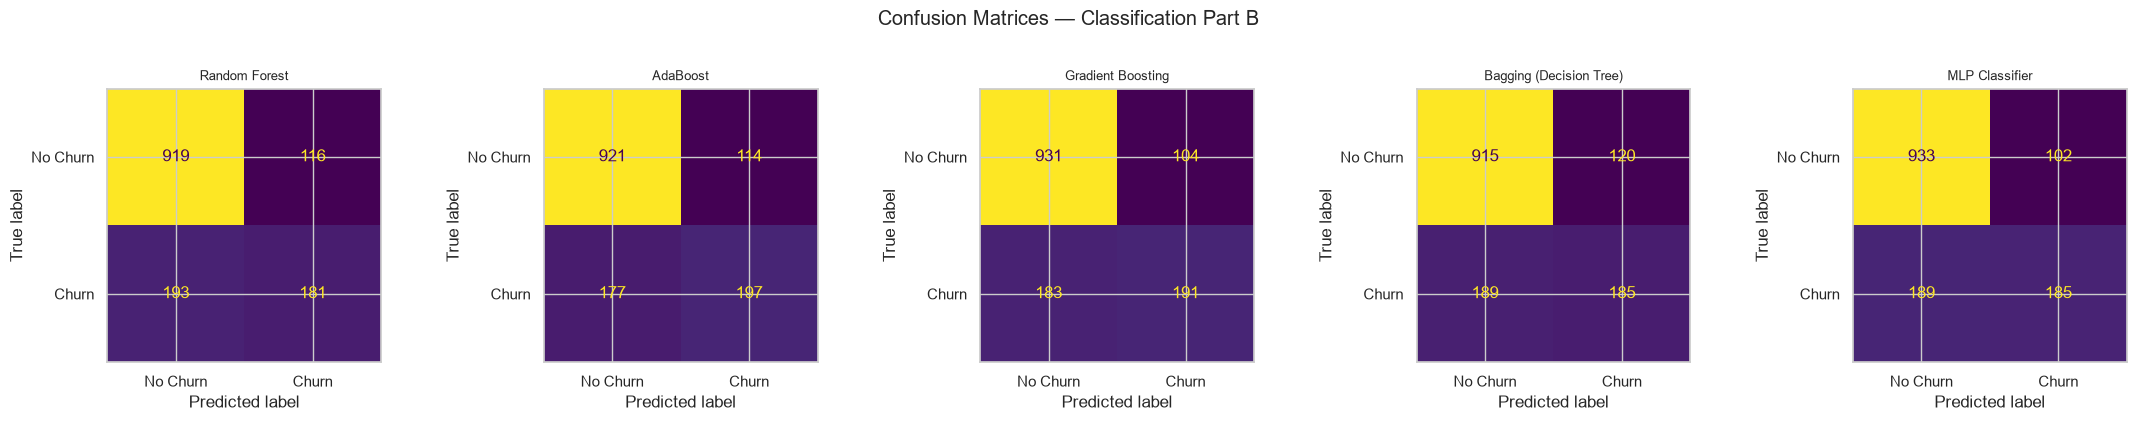

In [12]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, name in zip(axes, models_partB):
    cm = confusion_matrix(y_test, fitted[name].predict(X_test))
    ConfusionMatrixDisplay(cm, display_labels=['No Churn', 'Churn']).plot(ax=ax, colorbar=False)
    ax.set_title(name.split('. ')[1], fontsize=9)
plt.suptitle('Confusion Matrices — Classification Part B', y=1.03)
plt.tight_layout()
plt.show()

### ROC curves — Part B

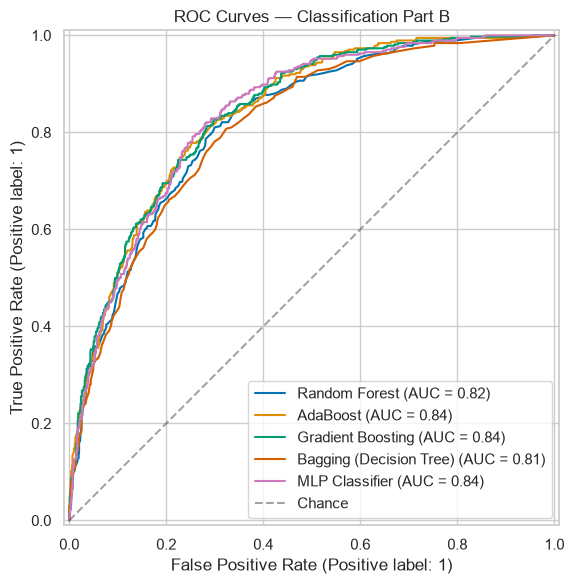

In [13]:
plt.figure(figsize=(7, 6))
for name in models_partB:
    RocCurveDisplay.from_predictions(y_test, probas[name], name=name.split('. ')[1], ax=plt.gca())
plt.plot([0, 1], [0, 1], 'k--', alpha=0.4, label='Chance')
plt.title('ROC Curves — Classification Part B')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()